# Dynamic Network Flow Graph (Source -> Robots -> Tasks -> Sink)

In [2]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import math
import networkx as nx

from environment import Environment
from robots import RobotFleet
from tasks import TaskManager
from network_flow import build_flow_graph, edmonds_karp_max_flow, flow_to_assignment, SOURCE, SINK

DATASET_ROOT = "C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/data/dataset"
env = Environment(DATASET_ROOT)
fleet = RobotFleet(DATASET_ROOT)
tm = TaskManager(DATASET_ROOT)


## Build the graph

In [3]:
def euclid(r, t):
    return math.hypot(r.x - t.x, r.y - t.y)

G = build_flow_graph(list(fleet.robots.values()), tm.active_tasks(), distance_fn=euclid)
n_robots = sum(1 for n, d in G.nodes(data=True) if d.get('kind') == 'robot')
n_tasks = sum(1 for n, d in G.nodes(data=True) if d.get('kind') == 'task')
n_edges = sum(1 for u, v in G.edges() if u.startswith('R:') and v.startswith('T:'))
print(f"Robot nodes: {n_robots}, Task nodes: {n_tasks}, feasible robot-task edges: {n_edges}")
print(f"Total graph nodes: {G.number_of_nodes()}, total edges: {G.number_of_edges()}")


Robot nodes: 12, Task nodes: 30, feasible robot-task edges: 101
Total graph nodes: 44, total edges: 143


## Run Edmonds-Karp (BFS-based Ford-Fulkerson)

In [4]:
max_flow, flow_dict = edmonds_karp_max_flow(G)
print(f"Max flow (feasible pairings found): {max_flow}")

# Cross-check against networkx's independent max-flow solver
nx_flow_value = nx.maximum_flow_value(G, SOURCE, SINK, capacity='capacity')
assert max_flow == nx_flow_value
print(f"Cross-checked against networkx.maximum_flow_value: {nx_flow_value} -- MATCH")

assignment = flow_to_assignment(flow_dict)
print(f"\n{len(assignment)} / {len(fleet.robots)} robots assigned by the flow-baseline:")
for rid, tid in sorted(assignment.items()):
    print(f"  {rid} -> {tid}")


Max flow (feasible pairings found): 12
Cross-checked against networkx.maximum_flow_value: 12 -- MATCH

12 / 12 robots assigned by the flow-baseline:
  UAV01 -> T21
  UAV02 -> T22
  UAV03 -> T23
  UAV04 -> T24
  UGV01 -> T02
  UGV02 -> T01
  UGV03 -> T03
  UGV04 -> T04
  USV01 -> T11
  USV02 -> T12
  USV03 -> T13
  USV04 -> T14


In [5]:
import matplotlib.pyplot as plt

In [6]:
# Identify nodes using the attributes created by build_flow_graph()

source_nodes = [
    n for n, d in G.nodes(data=True)
    if n == SOURCE
]

sink_nodes = [
    n for n, d in G.nodes(data=True)
    if n == SINK
]

robot_nodes = [
    n for n, d in G.nodes(data=True)
    if d.get("kind") == "robot"
]

task_nodes = [
    n for n, d in G.nodes(data=True)
    if d.get("kind") == "task"
]

print("Source nodes:", source_nodes)
print("Robot nodes:", len(robot_nodes))
print("Task nodes:", len(task_nodes))
print("Sink nodes:", sink_nodes)

Source nodes: ['SOURCE']
Robot nodes: 12
Task nodes: 30
Sink nodes: ['SINK']


In [7]:
# Layered layout:
# SOURCE -> ROBOTS -> TASKS -> SINK

pos = {}

# Source and sink
pos[SOURCE] = (0, 0)
pos[SINK] = (10, 0)

# Robot layer
robot_spacing = max(len(robot_nodes), 1)

for i, robot_id in enumerate(sorted(robot_nodes)):
    pos[robot_id] = (
        3,
        robot_spacing - i
    )

# Task layer
task_spacing = max(len(task_nodes), 1)

for i, task_id in enumerate(sorted(task_nodes)):
    pos[task_id] = (
        7,
        task_spacing - i
    )

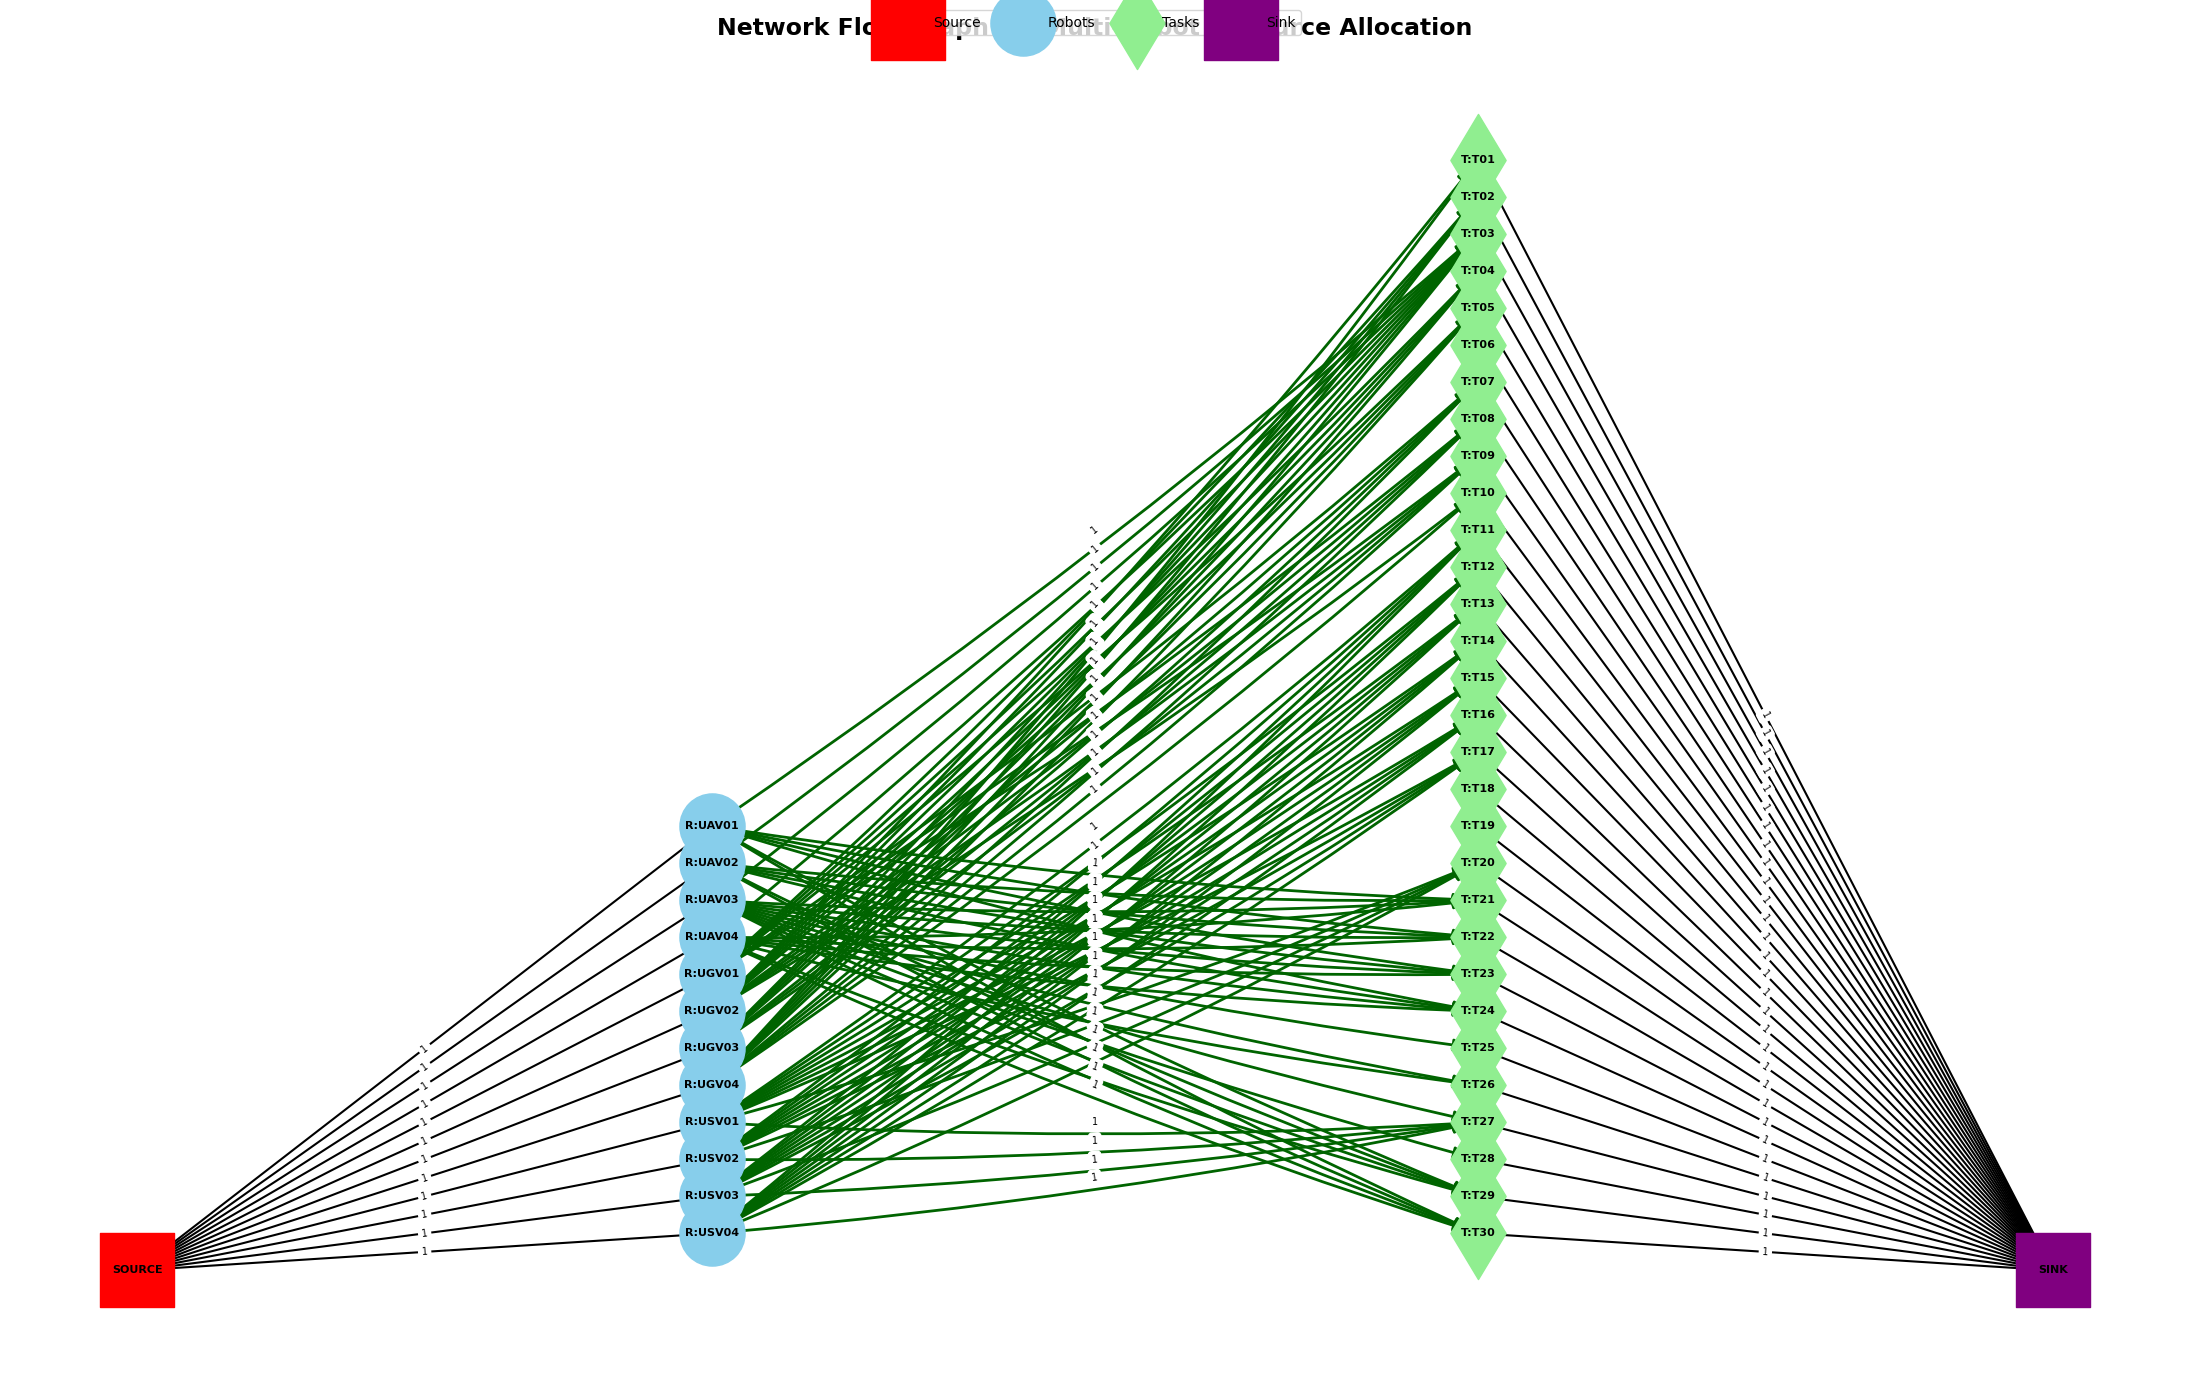

In [8]:
plt.figure(figsize=(22, 14))

# Draw source
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=source_nodes,
    node_color="red",
    node_shape="s",
    node_size=2800,
    label="Source"
)

# Draw robot nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=robot_nodes,
    node_color="skyblue",
    node_shape="o",
    node_size=2200,
    label="Robots"
)

# Draw task nodes
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=task_nodes,
    node_color="lightgreen",
    node_shape="d",
    node_size=2200,
    label="Tasks"
)

# Draw sink
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=sink_nodes,
    node_color="purple",
    node_shape="s",
    node_size=2800,
    label="Sink"
)

# Separate edge categories
source_robot_edges = [
    (u, v) for u, v in G.edges()
    if u == SOURCE and v in robot_nodes
]

robot_task_edges = [
    (u, v) for u, v in G.edges()
    if u in robot_nodes and v in task_nodes
]

task_sink_edges = [
    (u, v) for u, v in G.edges()
    if u in task_nodes and v == SINK
]

# Draw source-to-robot edges
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=source_robot_edges,
    edge_color="black",
    width=1.5,
    arrows=True,
    arrowsize=18
)

# Draw feasible robot-to-task edges
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=robot_task_edges,
    edge_color="darkgreen",
    width=2,
    arrows=True,
    arrowsize=18,
    connectionstyle="arc3,rad=0.03"
)

# Draw task-to-sink edges
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=task_sink_edges,
    edge_color="black",
    width=1.5,
    arrows=True,
    arrowsize=18
)

# Draw node labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    font_weight="bold"
)

# Display edge capacities
capacity_labels = nx.get_edge_attributes(G, "capacity")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=capacity_labels,
    font_size=7
)

plt.title(
    "Network Flow Graph for Multi-Robot Resource Allocation",
    fontsize=17,
    fontweight="bold"
)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4
)

plt.axis("off")
plt.tight_layout()
plt.show()

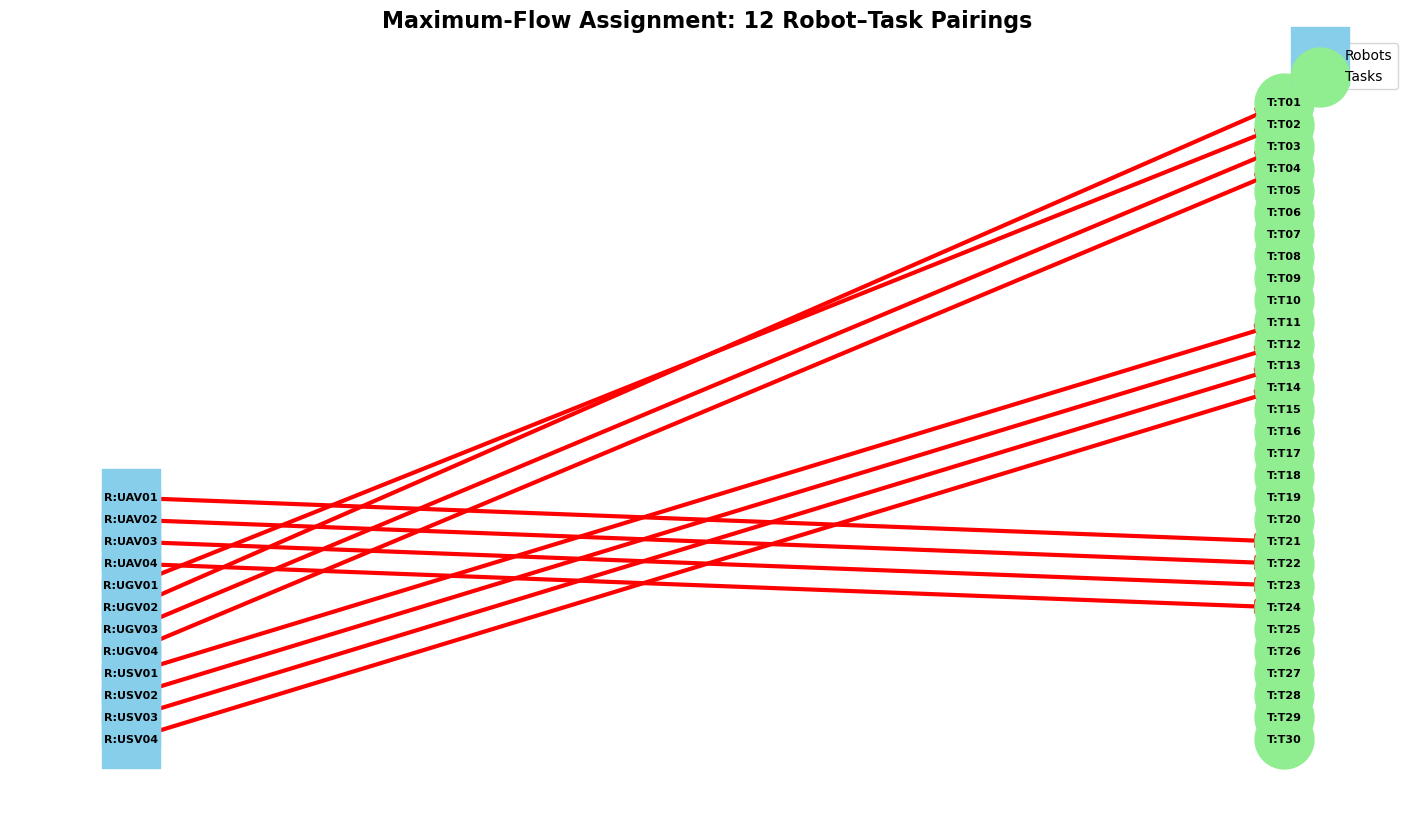

In [11]:
# Normalize assignment IDs to graph node IDs
def normalize_node(value, prefix):
    value = str(value)

    if value in G:
        return value

    graph_id = f"{prefix}:{value}"

    if graph_id in G:
        return graph_id

    return None


assigned_edges = []

for rid, tid in assignment.items():
    robot_node = normalize_node(rid, "R")
    task_node = normalize_node(tid, "T")

    if robot_node and task_node:
        assigned_edges.append((robot_node, task_node))


plt.figure(figsize=(18, 10))

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=robot_nodes,
    node_color="skyblue",
    node_size=1800,
    node_shape="s",
    label="Robots"
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=task_nodes,
    node_color="lightgreen",
    node_size=1800,
    node_shape="o",
    label="Tasks"
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=assigned_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    font_weight="bold"
)

plt.title(
    f"Maximum-Flow Assignment: {len(assigned_edges)} Robot–Task Pairings",
    fontsize=16,
    fontweight="bold"
)

plt.legend()
plt.axis("off")
plt.show()

In [10]:
max_flow, flow_dict = edmonds_karp_max_flow(G)
assignment = flow_to_assignment(flow_dict)